<a href="https://colab.research.google.com/github/licky2435/HospitalManagement-System/blob/main/student_mark_predictor_by_ml.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Business problem

In [1]:
#import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# load data set

In [6]:
path = r"Student_Marks_Updated.csv"
df = pd.read_csv (path)

In [8]:
df.head()

,number_courses,time_study,Marks,Result
0,3,4.508,19.202,Fail
1,4,0.096,7.734,Fail
2,4,3.133,13.811,Fail
3,6,7.909,53.018,Pass
4,8,7.811,55.299,Pass


In [10]:
df.tail()

,number_courses,time_study,Marks,Result
95,6,3.561,19.128,Fail
96,3,0.301,5.609,Fail
97,4,7.163,41.444,Pass
98,7,0.309,12.027,Fail
99,3,6.335,32.357,Fail


In [12]:
df.shape

(100, 4)

# discover and visualize the data to gain insights

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   number_courses  100 non-null    int64  
 1   time_study      100 non-null    float64
 2   Marks           100 non-null    float64
 3   Result          100 non-null    object 
dtypes: float64(2), int64(1), object(1)
memory usage: 3.3+ KB


In [14]:
df.describe()

,number_courses,time_study,Marks
count,100.000000,100.000000,100.000000
mean,5.290000,4.077140,24.417690
std,1.799523,2.372914,14.326199
min,3.000000,0.096000,5.609000
25%,4.000000,2.058500,12.633000
50%,5.000000,4.022000,20.059500
75%,7.000000,6.179250,36.676250
max,8.000000,7.957000,55.299000


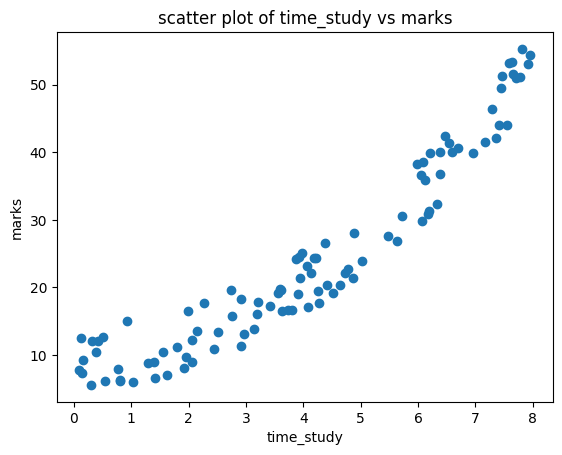

In [15]:
plt.scatter(x= df.time_study, y=df.Marks)
plt.xlabel("time_study")
plt.ylabel("marks")
plt.title("scatter plot of time_study vs marks")
plt.show()

# prepare the data for machine learning algorithms

In [16]:
#data cleaning

In [21]:
df.isnull(). sum()

,0
number_courses,0
time_study,0
Marks,0
Result,0


In [22]:
#split dataset

In [35]:
X = df.drop(columns=["Marks", "Result"])
Y = df["Marks"]
print("shape of x = ", X.shape)
print("shape of y = ", Y.shape)

shape of x =  (100, 2)
shape of y =  (100,)


In [38]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=51)
print("shape of X_train = ", X_train.shape)
print("shape of Y_train = ", Y_train.shape)
print("shape of X_test = ", X_test.shape)
print("shape of Y_test = ", Y_test.shape)

shape of X_train =  (80, 2)
shape of Y_train =  (80,)
shape of X_test =  (20, 2)
shape of Y_test =  (20,)


# select a model and train it

In [40]:
#y = m*x + c
from sklearn.linear_model import LinearRegression
lr = LinearRegression()


In [41]:
lr.fit(X_train, Y_train)

LinearRegression()

In [43]:
lr.coef_

array([1.72426165, 5.30910245])

In [45]:
lr.intercept_

np.float64(-6.365330282872165)

In [52]:
m = 5.30
c = -6.36
y = m * 4 +c
y

14.84

In [57]:
y_pred = lr.predict(X_test)
display(y_pred)

array([15.62429795, 10.5222505 ,  7.95025162, 19.22917852, 45.26262365,
       28.54306339, 47.94902949, 48.89816219,  3.08128215,  3.07066394,
       23.40452633, 10.90570252, 20.69037834, 27.90716774, 47.99561477,
       17.16513431, 25.90391694, 25.90683276, 22.74088853, 38.56081719])

In [61]:
pd.DataFrame(np.c_[X_test, Y_test, y_pred], columns=["number_courses", "time_study", "actual_marks", "predicted_marks"])

,number_courses,time_study,actual_marks,predicted_marks
0,5.0,2.518,13.416,15.624298
1,5.0,1.557,10.429,10.522250
2,7.0,0.423,12.132,7.950252
3,5.0,3.197,16.106,19.229179
4,7.0,7.451,49.544,45.262624
5,8.0,3.977,25.133,28.543063
6,7.0,7.957,54.321,47.949029
7,8.0,7.811,55.299,48.898162
8,3.0,0.805,6.349,3.081282
9,3.0,0.803,6.217,3.070664


## Fine- tune your model

In [63]:
lr.score(X_test, Y_test)

0.9450617114572717

In [67]:
from sklearn.metrics import r2_score

# Calculate R-squared score
r2 = r2_score(Y_test, y_pred)
print(f"R-squared (R2) Score: {r2:.5f}")
print(f"This means the model explains {r2 * 100:.2f}% of the variance in the student marks.")

R-squared (R2) Score: 0.94506
This means the model explains 94.51% of the variance in the student marks.


In [78]:
from sklearn.metrics import mean_absolute_error

# Calculate Mean Absolute Error (MAE)
mae = mean_absolute_error(Y_test, y_pred)
print(f"Mean Absolute Error (MAE): {mae:.5f}")

Mean Absolute Error (MAE): 3.51104


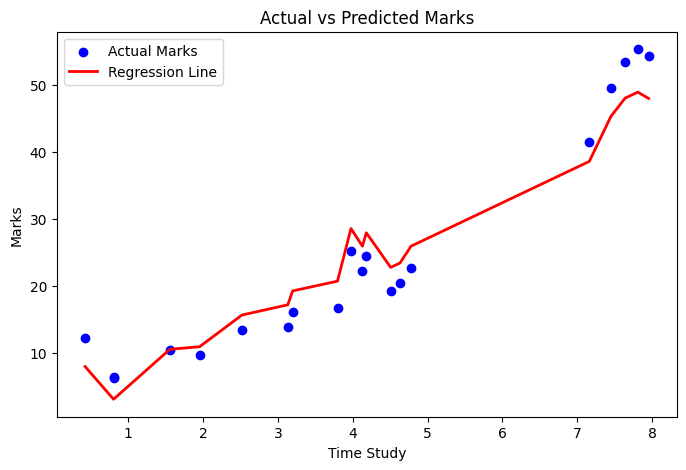

In [69]:
import matplotlib.pyplot as plt
import numpy as np

# Sort the test values by 'time_study' for a clean regression line plot
sort_idx = np.argsort(X_test['time_study'])
x_plot = X_test['time_study'].iloc[sort_idx]
y_actual = Y_test.iloc[sort_idx]
y_fit = y_pred[sort_idx]

plt.figure(figsize=(8, 5))
plt.scatter(x_plot, y_actual, color='blue', label='Actual Marks')
plt.plot(x_plot, y_fit, color='red', linewidth=2, label='Regression Line')
plt.xlabel('Time Study')
plt.ylabel('Marks')
plt.title('Actual vs Predicted Marks')
plt.legend()
plt.show()

## Present your solution

# save ML model

In [71]:
import joblib
joblib.dump(lr,"student mark predictor by ml.pkl")

['student mark predictor by ml.pkl']

In [73]:
model = joblib.load("student mark predictor by ml.pkl")

In [82]:
# Create a DataFrame with valid feature names to avoid warnings
input_data = pd.DataFrame([[5, 4.5]], columns=["number_courses", "time_study"])
prediction = model.predict(input_data)
print(f"Predicted Marks: {prediction[0]:.3f}")

Predicted Marks: 26.147


# Launch,Monitor,and Maintain Your System